# Subword Tokenization: BPE vs. WordPiece (IndicCorp v2)
### Introduction to Large Language Models — Assignment 3

This notebook implements **Byte-Pair Encoding (BPE)** and **WordPiece** entirely from scratch
(no `tokenizers`, `sentencepiece`, or other pre-built tokenizer libraries — only plain Python /
`collections` for the algorithms) on a single Indian language from IndicCorp v2, and studies how
tokenization behavior changes with (a) training data size and (b) vocabulary size.

**Pipeline**
1. Download one language's raw text, sentence-tokenize it (each corpus row is a paragraph, not a
   sentence), and build **length-stratified** train / dev / test splits (1000 dev + 1000 test
   sentences, chosen so their sentence-length distribution matches the overall corpus — not
   clustered around one length — with the rest going to train).
2. Implement BPE and WordPiece training + tokenization from scratch.
3. Train on **4 training-data sizes** (100,000 / 300,000 / 500,000 / 1,000,000 sentences) at a
   fixed vocabulary size, and tokenize dev/test with each — showing how tokenization changes with
   training data size.
4. Train on **3 vocabulary sizes** (20,000 / 30,000 / 50,000) at a fixed training size, and
   tokenize dev/test with each — showing the impact of vocabulary size on tokenization.

**A note on scale.** Training a *pure-Python* subword tokenizer on up to a million sentences with
up to a 50,000-token vocabulary is genuinely expensive — a naive implementation that rescans the
whole corpus for every single merge is far too slow at this scale. §4/§5 below use an
**incremental** training algorithm (only the words touched by a merge get their statistics
updated, instead of recomputing from scratch every iteration) plus training on **unique word
types weighted by frequency** rather than every raw token occurrence — the two standard tricks
that make BPE/WordPiece training tractable in practice. Even so, the largest configurations here
can take a while; §0 has a `QUICK_TEST` switch to sanity-check the whole pipeline on small numbers
before committing to a full run, and every training call exposes a `max_word_types` cap you can
lower if your machine is slow (rare, long-tail word types contribute almost nothing to the merge
statistics anyway).


## 0. Setup

In [19]:
%pip install -q requests huggingface_hub pandas pyarrow numpy regex tqdm matplotlib


Note: you may need to restart the kernel to use updated packages.


In [20]:
import os
import re
import time
import json
import pickle
import codecs
import fnmatch
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import regex  # unicode-aware \p{L}/\p{M} classes
import requests
from huggingface_hub import hf_hub_url, list_repo_files
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ---- choose your language here (any split from the Assignment 1 config works) ----
LANGUAGE = "guj_Gujr"      # Gujarati; change to your assigned language's HF split name
FILE_PATTERN = "data/gu.txt"  # matching raw-file pattern for LANGUAGE (see Assignment 1's
                               # SPLIT_FILE_PATTERNS dict for every language's path)

DEV_SIZE = 1000
TEST_SIZE = 1000
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]
DEFAULT_VOCAB_SIZE = 30_000     # used while varying training size in \u00a76
DEFAULT_TRAIN_SIZE = 1_000_000  # used while varying vocab size in \u00a77 (capped to what's available)

# QUICK_TEST shrinks every target size so you can sanity-check the whole notebook end-to-end in
# a couple of minutes before launching the real (slow) experiments. Set to False for the actual
# assignment run.
QUICK_TEST = False
if QUICK_TEST:
    DEV_SIZE, TEST_SIZE = 200, 200
    TRAIN_SIZES = [2_000, 5_000, 8_000, 12_000]
    VOCAB_SIZES = [500, 1_000, 2_000]
    DEFAULT_VOCAB_SIZE = 1_000
    DEFAULT_TRAIN_SIZE = 12_000

TOTAL_SENTENCES_NEEDED = max(TRAIN_SIZES + [DEFAULT_TRAIN_SIZE]) + DEV_SIZE + TEST_SIZE

DATA_DIR = "lab3_data"
ARTIFACTS_DIR = "lab3_artifacts"
for d in (DATA_DIR, ARTIFACTS_DIR):
    os.makedirs(d, exist_ok=True)

print(f"Language: {LANGUAGE}   QUICK_TEST={QUICK_TEST}")
print(f"Need at least {TOTAL_SENTENCES_NEEDED:,} sentences total "
      f"(train up to {max(TRAIN_SIZES + [DEFAULT_TRAIN_SIZE]):,} + dev {DEV_SIZE} + test {TEST_SIZE})")


Language: guj_Gujr   QUICK_TEST=False
Need at least 1,002,000 sentences total (train up to 1,000,000 + dev 1000 + test 1000)


## 1. Tokenizers (sentence + word) — same approach as Assignment 1

IndicCorp v2 stores one **paragraph** per row, so paragraphs need to be split into sentences
before anything else. We reuse the script-aware sentence tokenizer and the Unicode-aware word
tokenizer from Assignment 1.


In [21]:
SCRIPT_SENTENCE_ENDERS = {
    "Beng": ["।", "॥", ".", "?", "!"],
    "Deva": ["।", "॥", ".", "?", "!"],
    "Gujr": ["।", "॥", ".", "?", "!"],
    "Guru": ["।", "॥", ".", "?", "!"],
    "Orya": ["।", "॥", ".", "?", "!"],
    "Mtei": ["।", "॥", ".", "?", "!"],
    "Knda": [".", "?", "!", "।", "॥"],
    "Mlym": [".", "?", "!", "।"],
    "Taml": [".", "?", "!"],
    "Telu": [".", "?", "!", "।"],
    "Arab": ["۔", "؟", "!", ".", "?"],
    None:   [".", "?", "!"],
}
# infer the script suffix from LANGUAGE (e.g. "guj_Gujr" -> "Gujr"); None for khasi/santhali
_SCRIPT = LANGUAGE.split("_")[-1] if "_" in LANGUAGE else None
SENT_ENDERS = SCRIPT_SENTENCE_ENDERS.get(_SCRIPT, [".", "?", "!"])

_sent_split_re = re.compile("([" + "".join(re.escape(c) for c in SENT_ENDERS) + "]+)")

def sentence_tokenize(paragraph):
    paragraph = re.sub(r"\s+", " ", paragraph).strip()
    if not paragraph:
        return []
    ender_set = set(SENT_ENDERS)
    parts = _sent_split_re.split(paragraph)
    sentences, buf = [], ""
    for part in parts:
        if part and all(ch in ender_set for ch in part):
            buf += part
            s = buf.strip()
            if s:
                sentences.append(s)
            buf = ""
        else:
            buf += part
    if buf.strip():
        sentences.append(buf.strip())
    return sentences


_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    return _WORD_RE.findall(sentence)


## 2. Download & cache the language's sentences

Same direct-HTTP-streaming approach as the (updated) Assignment 1 download — plain
`requests` streaming over the raw `.txt` file with an incremental UTF-8 decoder, stopping once
we have enough sentences, rather than the slow `datasets`-library path. This time we need well
over a million sentences (for the largest training-size experiment), so this step genuinely
does take a while the first time — but it's cached to `lab3_data/{LANGUAGE}_sentences.parquet`
afterward, so it only needs to run once.


In [22]:
REPO_ID = "ai4bharat/IndicCorpV2"
HF_TOKEN = os.environ.get("HF_TOKEN")

_repo_files_cache = None
def _get_repo_files():
    global _repo_files_cache
    if _repo_files_cache is None:
        _repo_files_cache = list_repo_files(REPO_ID, repo_type="dataset")
    return _repo_files_cache

def resolve_file(pattern):
    if "*" not in pattern:
        return pattern
    files = _get_repo_files()
    matches = sorted(f for f in files if fnmatch.fnmatch(f, pattern))
    if not matches:
        raise FileNotFoundError(f"No repo files match {pattern!r}")
    return matches[0]

def stream_paragraphs(file_pattern, chunk_size=1 << 16, timeout=30):
    filename = resolve_file(file_pattern)
    url = hf_hub_url(REPO_ID, filename, repo_type="dataset")
    headers = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    resp = requests.get(url, headers=headers, stream=True, timeout=timeout)
    try:
        resp.raise_for_status()
        decoder = codecs.getincrementaldecoder("utf-8")(errors="ignore")
        buffer = ""
        for chunk in resp.iter_content(chunk_size=chunk_size):
            if not chunk:
                continue
            buffer += decoder.decode(chunk, final=False)
            *lines, buffer = buffer.split("\n")
            for line in lines:
                if line.strip():
                    yield line
        buffer += decoder.decode(b"", final=True)
        if buffer.strip():
            yield buffer
    finally:
        resp.close()


def collect_sentences(file_pattern, target_n, min_words=2, max_words=80,
                       cache_path=None, max_paragraphs=5_000_000):
    if cache_path and os.path.exists(cache_path):
        df = pd.read_parquet(cache_path)
        if len(df) >= target_n:
            return df

    seen = set()
    collected = []
    n_paragraphs = 0
    pbar = tqdm(total=target_n, desc="sentences")
    for paragraph in stream_paragraphs(file_pattern):
        n_paragraphs += 1
        for s in sentence_tokenize(paragraph):
            wc = len(word_tokenize(s))
            if wc < min_words or wc > max_words:
                continue
            if s in seen:
                continue
            seen.add(s)
            collected.append((s, wc))
            pbar.update(1)
            if len(collected) >= target_n:
                break
        if len(collected) >= target_n or n_paragraphs >= max_paragraphs:
            break
    pbar.close()

    if len(collected) < target_n:
        print(f"WARNING: only found {len(collected)}/{target_n} sentences after scanning "
              f"{n_paragraphs} paragraphs. All downstream sizes will be capped to what's available.")

    df = pd.DataFrame(collected, columns=["text", "length"])
    if cache_path:
        df.to_parquet(cache_path, index=False)
    return df


In [23]:
cache_path = os.path.join(DATA_DIR, f"{LANGUAGE}_sentences.parquet")
t0 = time.time()
sentences_df = collect_sentences(FILE_PATTERN, TOTAL_SENTENCES_NEEDED, cache_path=cache_path)
print(f"Collected {len(sentences_df):,} sentences in {time.time() - t0:.1f}s")
sentences_df["length"].describe()


sentences: 100%|██████████| 1002000/1002000 [00:12<00:00, 82269.72it/s]


Collected 1,002,000 sentences in 13.1s


count    1.002000e+06
mean     1.401123e+01
std      8.800814e+00
min      2.000000e+00
25%      8.000000e+00
50%      1.200000e+01
75%      1.800000e+01
max      8.000000e+01
Name: length, dtype: float64

## 3. Length-stratified train / dev / test split

The assignment requires dev and test sets that **don't cluster around one sentence length** —
we bin sentences by length rank into 10 equal-sized bins and sample proportionally from every
bin, so dev/test each reproduce the full corpus's length spread rather than, say, only grabbing
whatever the first 1000 rows happen to be (which tend to skew short). We verify this below with
summary statistics and a histogram.


In [24]:
def length_stratified_sample(df, n, n_bins=10, seed=0, exclude_idx=None):
    pool = df if exclude_idx is None else df.drop(index=exclude_idx)
    ranks = pool["length"].rank(method="first")
    bins = pd.qcut(ranks, q=min(n_bins, len(pool)), labels=False)
    rng = np.random.default_rng(seed)
    bin_ids = sorted(bins.unique())
    per_bin = n // len(bin_ids)
    remainder = n - per_bin * len(bin_ids)
    picked = []
    for i, b in enumerate(bin_ids):
        idx_in_bin = pool.index[bins == b].to_numpy()
        k = min(per_bin + (1 if i < remainder else 0), len(idx_in_bin))
        picked.extend(rng.choice(idx_in_bin, size=k, replace=False).tolist())
    return pd.Index(picked)


dev_idx = length_stratified_sample(sentences_df, DEV_SIZE, seed=RANDOM_SEED + 1)
test_idx = length_stratified_sample(sentences_df, TEST_SIZE, seed=RANDOM_SEED + 2, exclude_idx=dev_idx)

dev_df = sentences_df.loc[dev_idx].reset_index(drop=True)
test_df = sentences_df.loc[test_idx].reset_index(drop=True)
train_pool_df = sentences_df.drop(index=dev_idx.union(test_idx)).reset_index(drop=True)

print(f"dev: {len(dev_df)}   test: {len(test_df)}   train pool: {len(train_pool_df)}")
print(f"overlap dev/test: {len(dev_idx.intersection(test_idx))} (should be 0)")

for name, d in [("full corpus", sentences_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:12s} length: mean={d['length'].mean():.1f}  std={d['length'].std():.1f}  "
          f"min={d['length'].min()}  max={d['length'].max()}")


dev: 1000   test: 1000   train pool: 1000000
overlap dev/test: 0 (should be 0)
full corpus  length: mean=14.0  std=8.8  min=2  max=80
dev          length: mean=14.1  std=9.1  min=2  max=78
test         length: mean=14.1  std=9.3  min=2  max=79


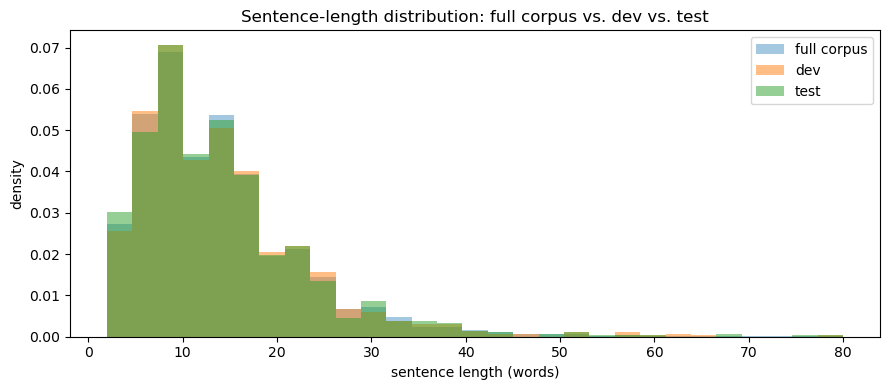

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(sentences_df["length"].min(), sentences_df["length"].max(), 30)
ax.hist(sentences_df["length"], bins=bins, alpha=0.4, density=True, label="full corpus")
ax.hist(dev_df["length"], bins=bins, alpha=0.5, density=True, label="dev")
ax.hist(test_df["length"], bins=bins, alpha=0.5, density=True, label="test")
ax.set_xlabel("sentence length (words)"); ax.set_ylabel("density")
ax.set_title("Sentence-length distribution: full corpus vs. dev vs. test")
ax.legend()
plt.tight_layout()
plt.show()


In [26]:
for name, d in [("dev", dev_df), ("test", test_df)]:
    d.to_parquet(os.path.join(DATA_DIR, f"{LANGUAGE}_{name}.parquet"), index=False)
train_pool_df.to_parquet(os.path.join(DATA_DIR, f"{LANGUAGE}_train_pool.parquet"), index=False)
print("Saved dev/test/train_pool splits to", DATA_DIR)


Saved dev/test/train_pool splits to lab3_data


## 4. Byte-Pair Encoding (BPE) — from scratch

**Training.** Represent every unique training word as a sequence of characters, with an
end-of-word marker `</w>` appended to the last character (so the model can tell "a word ending
in *-est*" apart from "*-est* followed by more characters"). Repeatedly find the **most
frequent adjacent symbol pair** across the (word-frequency-weighted) training vocabulary and
merge it into a single new symbol, recording each merge in order:

$$\text{best\_pair} = \arg\max_{(a,b)} \sum_{w \,:\, (a,b) \in w} \text{freq}(w)$$

This repeats until the vocabulary (initial character alphabet + merges) reaches `vocab_size`.

**Tokenizing new text.** Split the word into characters (+ `</w>`), then repeatedly apply the
**earliest-learned applicable merge** (not just any applicable merge) until no merge from the
learned list applies — this is what makes BPE tokenization deterministic and consistent with how
it was trained.

**Efficiency.** A naive implementation recomputes pair frequencies over the *entire* vocabulary
after every single merge — with a target vocabulary of 20k–50k that's 20,000–50,000 full
rescans. Instead we maintain the pair-frequency table incrementally: an index
`pair_to_words[pair]` tracks exactly which words contain each pair, so a merge only needs to
update the (typically small) set of words actually containing the merged pair, not the whole
corpus.


In [27]:
BPE_END = "</w>"

def _bpe_word_to_symbols(word):
    if not word:
        return []
    return list(word[:-1]) + [word[-1] + BPE_END]

def _bpe_merge_in_word(word, pair):
    a, b = pair
    merged = a + b
    out = []
    i, n = 0, len(word)
    while i < n:
        if i < n - 1 and word[i] == a and word[i + 1] == b:
            out.append(merged); i += 2
        else:
            out.append(word[i]); i += 1
    return tuple(out)


def train_bpe(word_freqs_raw, vocab_size, max_word_types=None, verbose=False):
    """word_freqs_raw: dict[str -> int] mapping a training word to its frequency.
    max_word_types: if set, keep only the top-K most frequent unique words before training
    (a standard practical speedup -- long-tail rare words barely affect merge statistics).
    Returns (merges: ordered list[(str,str)], vocab: set[str])."""
    if max_word_types and len(word_freqs_raw) > max_word_types:
        word_freqs_raw = dict(sorted(word_freqs_raw.items(), key=lambda kv: -kv[1])[:max_word_types])

    word_freqs = {tuple(_bpe_word_to_symbols(w)): f for w, f in word_freqs_raw.items()}

    vocab = set()
    for w in word_freqs:
        vocab.update(w)

    pair_freq = Counter()
    pair_to_words = defaultdict(set)
    for word, freq in word_freqs.items():
        for i in range(len(word) - 1):
            p = (word[i], word[i + 1])
            pair_freq[p] += freq
            pair_to_words[p].add(word)

    merges = []
    pbar = tqdm(total=max(vocab_size - len(vocab), 0), desc="training BPE", leave=False)
    while len(vocab) < vocab_size and pair_freq:
        best_pair = max(pair_freq.items(), key=lambda kv: (kv[1], kv[0]))[0]
        if pair_freq[best_pair] < 1:
            break

        for old_word in list(pair_to_words[best_pair]):
            freq = word_freqs.pop(old_word)
            for i in range(len(old_word) - 1):
                p = (old_word[i], old_word[i + 1])
                pair_freq[p] -= freq
                if pair_freq[p] <= 0:
                    del pair_freq[p]
                pair_to_words[p].discard(old_word)

            new_word = _bpe_merge_in_word(old_word, best_pair)
            word_freqs[new_word] = word_freqs.get(new_word, 0) + freq

            for i in range(len(new_word) - 1):
                p = (new_word[i], new_word[i + 1])
                pair_freq[p] += freq
                pair_to_words[p].add(new_word)

        vocab.add(best_pair[0] + best_pair[1])
        merges.append(best_pair)
        pbar.update(1)
        if verbose and len(merges) % 1000 == 0:
            print(f"  {len(merges)} merges, vocab={len(vocab)}")
    pbar.close()
    return merges, vocab


def apply_bpe(word, merge_rank):
    """merge_rank: dict[(str,str) -> int] mapping each learned merge to its learned order
    (lower = learned earlier = applied first)."""
    symbols = _bpe_word_to_symbols(word)
    while len(symbols) > 1:
        candidates = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merge_rank[p], p) for p in candidates if p in merge_rank]
        if not ranked:
            break
        _, best_pair = min(ranked)
        symbols = list(_bpe_merge_in_word(tuple(symbols), best_pair))
    return symbols


## 5. WordPiece — from scratch

WordPiece uses the same "merge the best adjacent pair repeatedly" structure as BPE, but scores
candidate merges by **normalized mutual information** rather than raw frequency, so it prefers
merges between symbols that co-occur *more than chance* would predict — not just symbols that are
each individually common:

$$\text{score}(a, b) = \frac{\text{freq}(a, b)}{\text{freq}(a) \cdot \text{freq}(b)}$$

Words are split into characters where every character **except the first** of a word is prefixed
with `##` (marking "this piece continues the previous one," BERT-style), e.g. `"hug"` →
`["h", "##u", "##g"]`. Merging `(A, B)` (where `B` always carries the `##` prefix by
construction) produces `A + B[2:]` — i.e. it keeps `A`'s own prefix (or lack thereof) and drops
`B`'s now-internal `##` marker.

**Tokenizing new text** uses WordPiece's own greedy **longest-match-first** algorithm (this is
different from BPE's "replay the merges in order" — it's how BERT's actual tokenizer works): for
each word, repeatedly find the longest substring starting at the current position that exists in
the learned vocabulary (as a bare token if it's the start of the word, or with a `##` prefix
otherwise), consume it, and continue from where it left off. If no prefix matches at some
position, the whole word becomes `[UNK]`.


In [28]:
def _wp_word_to_symbols(word):
    if not word:
        return []
    return [word[0]] + ["##" + c for c in word[1:]]

def _wp_merge_symbol(a, b):
    return a + b[2:]  # b always starts with "##" by construction


def train_wordpiece(word_freqs_raw, vocab_size, max_word_types=None, verbose=False):
    if max_word_types and len(word_freqs_raw) > max_word_types:
        word_freqs_raw = dict(sorted(word_freqs_raw.items(), key=lambda kv: -kv[1])[:max_word_types])

    word_freqs = {tuple(_wp_word_to_symbols(w)): f for w, f in word_freqs_raw.items()}

    vocab = set()
    for w in word_freqs:
        vocab.update(w)

    pair_freq = Counter()
    sym_freq = Counter()
    pair_to_words = defaultdict(set)
    for word, freq in word_freqs.items():
        for s in word:
            sym_freq[s] += freq
        for i in range(len(word) - 1):
            p = (word[i], word[i + 1])
            pair_freq[p] += freq
            pair_to_words[p].add(word)

    def score(pair):
        f = pair_freq.get(pair, 0)
        if f <= 0:
            return -1.0
        a, b = pair
        return f / (sym_freq[a] * sym_freq[b])

    pbar = tqdm(total=max(vocab_size - len(vocab), 0), desc="training WordPiece", leave=False)
    n_merges = 0
    while len(vocab) < vocab_size and pair_freq:
        best_pair = max(pair_freq.keys(), key=lambda p: (score(p), p))
        if pair_freq[best_pair] < 1:
            break

        for old_word in list(pair_to_words[best_pair]):
            freq = word_freqs.pop(old_word)
            for i in range(len(old_word) - 1):
                p = (old_word[i], old_word[i + 1])
                pair_freq[p] -= freq
                if pair_freq[p] <= 0:
                    del pair_freq[p]
                pair_to_words[p].discard(old_word)
            for s in old_word:
                sym_freq[s] -= freq

            merged_sym = _wp_merge_symbol(*best_pair)
            new_word, i, n = [], 0, len(old_word)
            while i < n:
                if i < n - 1 and (old_word[i], old_word[i + 1]) == best_pair:
                    new_word.append(merged_sym); i += 2
                else:
                    new_word.append(old_word[i]); i += 1
            new_word = tuple(new_word)
            word_freqs[new_word] = word_freqs.get(new_word, 0) + freq

            for s in new_word:
                sym_freq[s] += freq
            for i in range(len(new_word) - 1):
                p = (new_word[i], new_word[i + 1])
                pair_freq[p] += freq
                pair_to_words[p].add(new_word)

        vocab.add(_wp_merge_symbol(*best_pair))
        n_merges += 1
        pbar.update(1)
        if verbose and n_merges % 1000 == 0:
            print(f"  {n_merges} merges, vocab={len(vocab)}")
    pbar.close()
    return vocab


def tokenize_wordpiece(word, vocab, unk_token="[UNK]"):
    if word == "":
        return []
    tokens, start, n = [], 0, len(word)
    while start < n:
        end = n
        cur = None
        while start < end:
            piece = word[start:end]
            candidate = piece if start == 0 else "##" + piece
            if candidate in vocab:
                cur = candidate
                break
            end -= 1
        if cur is None:
            return [unk_token]
        tokens.append(cur)
        start = end
    return tokens


## 6. Word-frequency table & evaluation metrics

Both trainers take a `word -> frequency` table as input, not raw sentences — we build this once
per training-size subset (§7). For evaluation, we report, per configuration:

* **avg tokens/sentence** on dev/test — fewer tokens per sentence means more *compression*
  (bigger, more specific subwords being reused successfully)
  * **avg characters/token** — the inverse view of the same thing
* **[UNK] rate** (WordPiece only — BPE always falls back to individual characters, which are
  guaranteed to be in-vocabulary, so it never produces `[UNK]`)
* **vocab utilization** — the fraction of the trained vocabulary that actually gets used at least
  once across dev+test


In [29]:
def build_word_freqs(sentences):
    freqs = Counter()
    for s in sentences:
        freqs.update(word_tokenize(s))
    return dict(freqs)


def evaluate_bpe(merges, dev_sentences, test_sentences):
    merge_rank = {p: i for i, p in enumerate(merges)}
    results = {}
    used_symbols = set()
    for split_name, sents in [("dev", dev_sentences), ("test", test_sentences)]:
        n_tokens, n_chars, n_words = 0, 0, 0
        for s in sents:
            for w in word_tokenize(s):
                toks = apply_bpe(w, merge_rank)
                used_symbols.update(toks)
                n_tokens += len(toks)
                n_chars += len(w)
                n_words += 1
        results[split_name] = {
            "avg_tokens_per_sentence": n_tokens / len(sents) if sents else 0.0,
            "avg_tokens_per_word": n_tokens / n_words if n_words else 0.0,
            "avg_chars_per_token": n_chars / n_tokens if n_tokens else 0.0,
            "unk_rate": 0.0,
        }
    results["vocab_utilization"] = len(used_symbols)
    return results


def evaluate_wordpiece(vocab, dev_sentences, test_sentences):
    results = {}
    used_symbols = set()
    for split_name, sents in [("dev", dev_sentences), ("test", test_sentences)]:
        n_tokens, n_chars, n_words, n_unk = 0, 0, 0, 0
        for s in sents:
            for w in word_tokenize(s):
                toks = tokenize_wordpiece(w, vocab)
                used_symbols.update(toks)
                n_tokens += len(toks)
                n_chars += len(w)
                n_words += 1
                if toks == ["[UNK]"]:
                    n_unk += 1
        results[split_name] = {
            "avg_tokens_per_sentence": n_tokens / len(sents) if sents else 0.0,
            "avg_tokens_per_word": n_tokens / n_words if n_words else 0.0,
            "avg_chars_per_token": n_chars / n_tokens if n_tokens else 0.0,
            "unk_rate": n_unk / n_words if n_words else 0.0,
        }
    results["vocab_utilization"] = len(used_symbols)
    return results


## 7. Experiment A — varying training data size

Fixed vocabulary size (`DEFAULT_VOCAB_SIZE`); training size varies over
`TRAIN_SIZES` = 100,000 / 300,000 / 500,000 / 1,000,000 sentences (each size uses that many
sentences **from the front of the shared training pool**, so smaller-size runs are strict subsets
of larger ones — an apples-to-apples comparison of "more data, same everything else").


In [30]:
dev_sentences = dev_df["text"].tolist()
test_sentences = test_df["text"].tolist()
all_train_sentences = train_pool_df["text"].tolist()

size_results = []
size_artifacts = {}

for size in TRAIN_SIZES:
    actual_size = min(size, len(all_train_sentences))
    if actual_size < size:
        print(f"WARNING: requested {size:,} training sentences but only {actual_size:,} available; "
              f"using {actual_size:,}.")
    train_subset = all_train_sentences[:actual_size]
    word_freqs = build_word_freqs(train_subset)
    print(f"\n=== training size {size:,} (actual {actual_size:,} sentences, "
          f"{len(word_freqs):,} unique word types) ===")

    t0 = time.time()
    merges, bpe_vocab = train_bpe(word_freqs, DEFAULT_VOCAB_SIZE, max_word_types=200_000)
    bpe_time = time.time() - t0
    bpe_eval = evaluate_bpe(merges, dev_sentences, test_sentences)
    print(f"BPE: {len(bpe_vocab)} symbols, {bpe_time:.1f}s, "
          f"test avg_tokens/sentence={bpe_eval['test']['avg_tokens_per_sentence']:.2f}")

    t0 = time.time()
    wp_vocab = train_wordpiece(word_freqs, DEFAULT_VOCAB_SIZE, max_word_types=200_000)
    wp_time = time.time() - t0
    wp_eval = evaluate_wordpiece(wp_vocab, dev_sentences, test_sentences)
    print(f"WordPiece: {len(wp_vocab)} symbols, {wp_time:.1f}s, "
          f"test avg_tokens/sentence={wp_eval['test']['avg_tokens_per_sentence']:.2f}, "
          f"unk_rate={wp_eval['test']['unk_rate']:.4f}")

    size_results.append({"train_size": size, "actual_train_size": actual_size, "n_unique_words": len(word_freqs),
                          "algo": "BPE", "train_time_s": bpe_time, **{f"test_{k}": v for k, v in bpe_eval["test"].items()},
                          "vocab_utilization": bpe_eval["vocab_utilization"]})
    size_results.append({"train_size": size, "actual_train_size": actual_size, "n_unique_words": len(word_freqs),
                          "algo": "WordPiece", "train_time_s": wp_time, **{f"test_{k}": v for k, v in wp_eval["test"].items()},
                          "vocab_utilization": wp_eval["vocab_utilization"]})
    size_artifacts[size] = {"bpe_merges": merges, "bpe_vocab": bpe_vocab, "wp_vocab": wp_vocab}

size_results_df = pd.DataFrame(size_results)
size_results_df



=== training size 100,000 (actual 100,000 sentences, 131,262 unique word types) ===


BPE: 30000 symbols, 184.8s, test avg_tokens/sentence=17.28


WordPiece: 30000 symbols, 35.6s, test avg_tokens/sentence=59.14, unk_rate=0.0000

=== training size 300,000 (actual 300,000 sentences, 252,328 unique word types) ===


BPE: 30000 symbols, 375.6s, test avg_tokens/sentence=17.23


WordPiece: 30000 symbols, 121.4s, test avg_tokens/sentence=67.35, unk_rate=0.0000

=== training size 500,000 (actual 500,000 sentences, 343,033 unique word types) ===


BPE: 30000 symbols, 4148.3s, test avg_tokens/sentence=17.23


WordPiece: 30000 symbols, 293.1s, test avg_tokens/sentence=66.82, unk_rate=0.0000

=== training size 1,000,000 (actual 1,000,000 sentences, 516,809 unique word types) ===


BPE: 30000 symbols, 5404.1s, test avg_tokens/sentence=17.22


WordPiece: 30000 symbols, 35.0s, test avg_tokens/sentence=63.79, unk_rate=0.0000


,train_size,actual_train_size,n_unique_words,algo,train_time_s,test_avg_tokens_per_sentence,test_avg_tokens_per_word,test_avg_chars_per_token,test_unk_rate,vocab_utilization
0,100000,100000,131262,BPE,184.771063,17.276,1.221178,3.965443,0.0,10729
1,100000,100000,131262,WordPiece,35.609563,59.144,4.180674,1.158309,0.0,1380
2,300000,300000,252328,BPE,375.592943,17.231,1.217997,3.975799,0.0,10796
3,300000,300000,252328,WordPiece,121.375565,67.351,4.760797,1.017164,0.0,697
4,500000,500000,343033,BPE,4148.340237,17.230,1.217926,3.976030,0.0,10779
5,500000,500000,343033,WordPiece,293.072155,66.821,4.723334,1.025232,0.0,744
6,1000000,1000000,516809,BPE,5404.099295,17.219,1.217149,3.978570,0.0,10760
7,1000000,1000000,516809,WordPiece,35.028514,63.788,4.508942,1.073979,0.0,1011


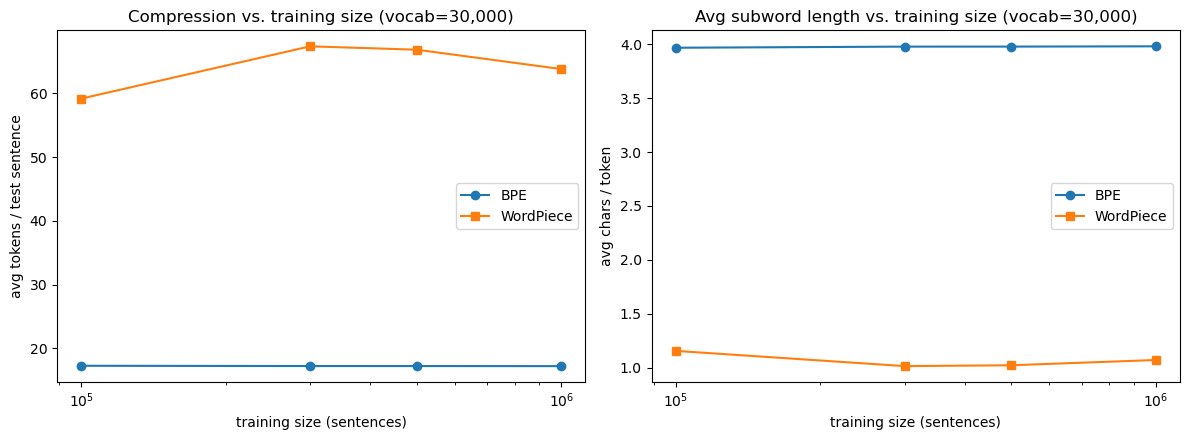

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for algo, marker in [("BPE", "o"), ("WordPiece", "s")]:
    sub = size_results_df[size_results_df["algo"] == algo]
    axes[0].plot(sub["train_size"], sub["test_avg_tokens_per_sentence"], marker=marker, label=algo)
    axes[1].plot(sub["train_size"], sub["test_avg_chars_per_token"], marker=marker, label=algo)
axes[0].set_xlabel("training size (sentences)"); axes[0].set_ylabel("avg tokens / test sentence")
axes[0].set_title(f"Compression vs. training size (vocab={DEFAULT_VOCAB_SIZE:,})")
axes[1].set_xlabel("training size (sentences)"); axes[1].set_ylabel("avg chars / token")
axes[1].set_title(f"Avg subword length vs. training size (vocab={DEFAULT_VOCAB_SIZE:,})")
for ax in axes:
    ax.legend(); ax.set_xscale("log")
plt.tight_layout()
plt.show()


## 8. Experiment B — varying vocabulary size

Fixed training size (`DEFAULT_TRAIN_SIZE`, capped to what's actually available); vocabulary size
varies over `VOCAB_SIZES` = 20,000 / 30,000 / 50,000.


In [32]:
vocab_train_size = min(DEFAULT_TRAIN_SIZE, len(all_train_sentences))
vocab_train_subset = all_train_sentences[:vocab_train_size]
vocab_word_freqs = build_word_freqs(vocab_train_subset)
print(f"Fixed training size for this experiment: {vocab_train_size:,} sentences, "
      f"{len(vocab_word_freqs):,} unique word types")

vocab_results = []
vocab_artifacts = {}

for vs in VOCAB_SIZES:
    print(f"\n=== vocab size {vs:,} ===")

    t0 = time.time()
    merges, bpe_vocab = train_bpe(vocab_word_freqs, vs, max_word_types=200_000)
    bpe_time = time.time() - t0
    bpe_eval = evaluate_bpe(merges, dev_sentences, test_sentences)
    print(f"BPE: {len(bpe_vocab)} symbols, {bpe_time:.1f}s, "
          f"test avg_tokens/sentence={bpe_eval['test']['avg_tokens_per_sentence']:.2f}")

    t0 = time.time()
    wp_vocab = train_wordpiece(vocab_word_freqs, vs, max_word_types=200_000)
    wp_time = time.time() - t0
    wp_eval = evaluate_wordpiece(wp_vocab, dev_sentences, test_sentences)
    print(f"WordPiece: {len(wp_vocab)} symbols, {wp_time:.1f}s, "
          f"test avg_tokens/sentence={wp_eval['test']['avg_tokens_per_sentence']:.2f}, "
          f"unk_rate={wp_eval['test']['unk_rate']:.4f}")

    vocab_results.append({"vocab_size": vs, "algo": "BPE", "actual_vocab_size": len(bpe_vocab), "train_time_s": bpe_time,
                           **{f"test_{k}": v for k, v in bpe_eval["test"].items()}, "vocab_utilization": bpe_eval["vocab_utilization"]})
    vocab_results.append({"vocab_size": vs, "algo": "WordPiece", "actual_vocab_size": len(wp_vocab), "train_time_s": wp_time,
                           **{f"test_{k}": v for k, v in wp_eval["test"].items()}, "vocab_utilization": wp_eval["vocab_utilization"]})
    vocab_artifacts[vs] = {"bpe_merges": merges, "bpe_vocab": bpe_vocab, "wp_vocab": wp_vocab}

vocab_results_df = pd.DataFrame(vocab_results)
vocab_results_df


Fixed training size for this experiment: 1,000,000 sentences, 516,809 unique word types

=== vocab size 20,000 ===


BPE: 20000 symbols, 147.4s, test avg_tokens/sentence=18.22


WordPiece: 20000 symbols, 23.2s, test avg_tokens/sentence=68.01, unk_rate=0.0000

=== vocab size 30,000 ===


BPE: 30000 symbols, 245.5s, test avg_tokens/sentence=17.22


WordPiece: 30000 symbols, 34.7s, test avg_tokens/sentence=63.79, unk_rate=0.0000

=== vocab size 50,000 ===


BPE: 50000 symbols, 432.0s, test avg_tokens/sentence=16.29


WordPiece: 50000 symbols, 91.7s, test avg_tokens/sentence=54.03, unk_rate=0.0000


,vocab_size,algo,actual_vocab_size,train_time_s,test_avg_tokens_per_sentence,test_avg_tokens_per_word,test_avg_chars_per_token,test_unk_rate,vocab_utilization
0,20000,BPE,20000,147.387786,18.224,1.288188,3.759164,0.0,9852
1,20000,WordPiece,20000,23.181053,68.010,4.807380,1.007308,0.0,390
2,30000,BPE,30000,245.536241,17.219,1.217149,3.978570,0.0,10760
3,30000,WordPiece,30000,34.663760,63.788,4.508942,1.073979,0.0,1011
4,50000,BPE,50000,431.967459,16.286,1.151198,4.206496,0.0,11391
5,50000,WordPiece,50000,91.702909,54.035,3.819538,1.267826,0.0,2061


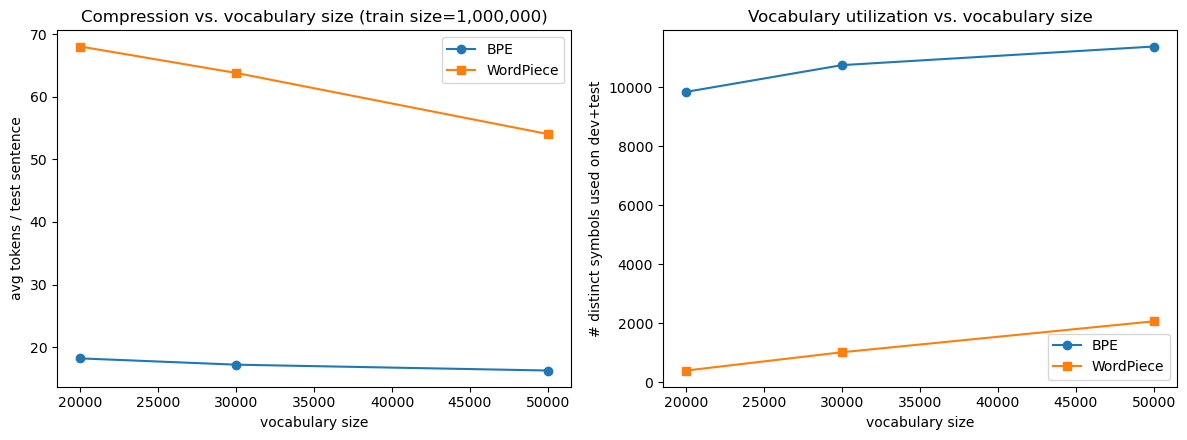

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for algo, marker in [("BPE", "o"), ("WordPiece", "s")]:
    sub = vocab_results_df[vocab_results_df["algo"] == algo]
    axes[0].plot(sub["vocab_size"], sub["test_avg_tokens_per_sentence"], marker=marker, label=algo)
    axes[1].plot(sub["vocab_size"], sub["vocab_utilization"], marker=marker, label=algo)
axes[0].set_xlabel("vocabulary size"); axes[0].set_ylabel("avg tokens / test sentence")
axes[0].set_title(f"Compression vs. vocabulary size (train size={vocab_train_size:,})")
axes[1].set_xlabel("vocabulary size"); axes[1].set_ylabel("# distinct symbols used on dev+test")
axes[1].set_title("Vocabulary utilization vs. vocabulary size")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


## 9. Qualitative comparison

A few dev sentences tokenized under the smallest and largest vocabulary sizes from Experiment B,
side by side, to see the segmentation granularity difference directly.


In [34]:
sample_sentences = dev_sentences[:5]
small_vs, large_vs = min(VOCAB_SIZES), max(VOCAB_SIZES)

for s in sample_sentences:
    print("SENTENCE:", s)
    for vs in (small_vs, large_vs):
        merges = vocab_artifacts[vs]["bpe_merges"]
        merge_rank = {p: i for i, p in enumerate(merges)}
        bpe_toks = [t for w in word_tokenize(s) for t in apply_bpe(w, merge_rank)]
        wp_toks = [t for w in word_tokenize(s) for t in tokenize_wordpiece(w, vocab_artifacts[vs]["wp_vocab"])]
        print(f"  vocab={vs:,}  BPE       : {bpe_toks}")
        print(f"  vocab={vs:,}  WordPiece : {wp_toks}")
    print()


SENTENCE: મહેશભાઇ વાટલીયા, ડો.
  vocab=20,000  BPE       : ['મહેશભાઇ</w>', 'વા', 'ટ', 'લીયા</w>', 'ડો</w>']
  vocab=20,000  WordPiece : ['મ', '##હ', '##ે', '##શ', '##ભ', '##ા', '##ઇ', 'વ', '##ા', '##ટ', '##લ', '##ી', '##ય', '##ા', 'ડ', '##ો']
  vocab=50,000  BPE       : ['મહેશભાઇ</w>', 'વાટ', 'લીયા</w>', 'ડો</w>']
  vocab=50,000  WordPiece : ['મહેશભ', '##ા', '##ઇ', 'વ', '##ા', '##ટ', '##લ', '##ી', '##ય', '##ા', 'ડ', '##ો']

SENTENCE: અને જે જીપની વાત છે.
  vocab=20,000  BPE       : ['અને</w>', 'જે</w>', 'જી', 'પની</w>', 'વાત</w>', 'છે</w>']
  vocab=20,000  WordPiece : ['અ', '##ન', '##ે', 'જ', '##ે', 'જ', '##ી', '##પ', '##ન', '##ી', 'વ', '##ા', '##ત', 'છ', '##ે']
  vocab=50,000  BPE       : ['અને</w>', 'જે</w>', 'જી', 'પની</w>', 'વાત</w>', 'છે</w>']
  vocab=50,000  WordPiece : ['અને', 'જ', '##ે', 'જ', '##ી', '##પ', '##ન', '##ી', 'વ', '##ા', '##ત', 'છે']

SENTENCE: ૧૨ ડોલર ઘટીને ૧૮.
  vocab=20,000  BPE       : ['૧૨</w>', 'ડોલર</w>', 'ઘટીને</w>', '૧૮</w>']
  vocab=20,000  WordPiece : ['૧૨

## 10. Save results

In [35]:
size_results_df.to_csv(os.path.join(ARTIFACTS_DIR, "results_by_train_size.csv"), index=False)
vocab_results_df.to_csv(os.path.join(ARTIFACTS_DIR, "results_by_vocab_size.csv"), index=False)

with open(os.path.join(ARTIFACTS_DIR, "size_experiment_artifacts.pkl"), "wb") as f:
    pickle.dump(size_artifacts, f)
with open(os.path.join(ARTIFACTS_DIR, "vocab_experiment_artifacts.pkl"), "wb") as f:
    pickle.dump(vocab_artifacts, f)

print("Saved comparison tables and trained BPE/WordPiece artifacts to", ARTIFACTS_DIR)


Saved comparison tables and trained BPE/WordPiece artifacts to lab3_artifacts
